# This is a sample Jupyter Notebook

Below is an example of a code cell. 
Put your cursor into the cell and press Shift+Enter to execute it and select the next one, or click 'Run Cell' button.

Press Double Shift to search everywhere for classes, files, tool windows, actions, and settings.

To learn more about Jupyter Notebooks in PyCharm, see [help](https://www.jetbrains.com/help/pycharm/ipython-notebook-support.html).
For an overview of PyCharm, go to Help -> Learn IDE features or refer to [our documentation](https://www.jetbrains.com/help/pycharm/getting-started.html).

In [1]:
import pandas as pd
from Bio import SeqIO
from Bio.SeqUtils import gc_fraction

In [2]:
cds_counts = []
gc_counts = []
with open("EC_Oag.gbk", "r") as handle:
    for record in SeqIO.parse(handle, "genbank"):
        cds_count = 0
        print(f"ID: {record.id}")
        print(f"Name: {record.name}")
        print(f"Description: {record.description}")
        print(f"Sequence Length: {len(record.seq)}")
        for feature in record.features:
            if feature.type == "CDS":
                cds_count += 1
        print(f"CDS: {cds_count}")
        cds_counts.append(cds_count)
        gc_counts.append(gc_fraction(record.seq)*100)
        print("-" * 40)

ID: NZ_CP023815.1
Name: NZ_CP023815.1
Description: NZ_CP023815.1, whole genome shotgun sequence
Sequence Length: 8685
CDS: 9
----------------------------------------
ID: NZ_CP044311.1
Name: NZ_CP044311.1
Description: NZ_CP044311.1, whole genome shotgun sequence
Sequence Length: 14698
CDS: 15
----------------------------------------
ID: NZ_AP027258.1
Name: NZ_AP027258.1
Description: NZ_AP027258.1, whole genome shotgun sequence
Sequence Length: 9377
CDS: 10
----------------------------------------
ID: NZ_CP100876.1
Name: NZ_CP100876.1
Description: NZ_CP100876.1, whole genome shotgun sequence
Sequence Length: 10878
CDS: 11
----------------------------------------
ID: NZ_AP027648.1
Name: NZ_AP027648.1
Description: NZ_AP027648.1, whole genome shotgun sequence
Sequence Length: 9433
CDS: 8
----------------------------------------
ID: NZ_CP122629.1
Name: NZ_CP122629.1
Description: NZ_CP122629.1, whole genome shotgun sequence
Sequence Length: 15398
CDS: 16
--------------------------------------

In [3]:
import plotly.express as px

fig = px.histogram(cds_counts)
fig.show()

In [4]:

fig = px.histogram(gc_counts)
fig.show()

In [5]:
fig = px.scatter(cds_counts, gc_counts)
fig.show()
fig.show()

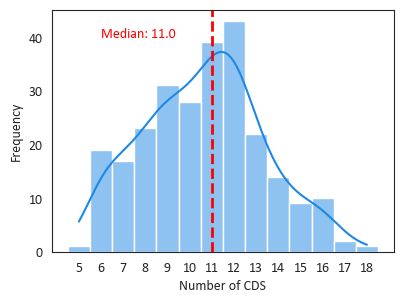

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import matplotlib as mpl
sns.set_style("white")
plt.figure(figsize=(4.135, 3.135))
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Calibri', 'DejaVu Sans'] # DejaVu Sans serves as a safe fallback
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
sns.histplot(cds_counts, kde=True, discrete=True, color="#1E88E5")
plt.xticks(range(min(cds_counts), max(cds_counts)+1, 1))
plt.axvline(x=np.median(cds_counts), color="red", linestyle="--", linewidth=2)
plt.text(x=6, y=40, s=f"Median: {round(np.median(cds_counts), 2)}", color="red")
plt.ylabel("Frequency")
plt.xlabel("Number of CDS")
plt.tight_layout()
plt.savefig("cds_histogram.pdf", bbox_inches='tight', format="pdf")
plt.show()

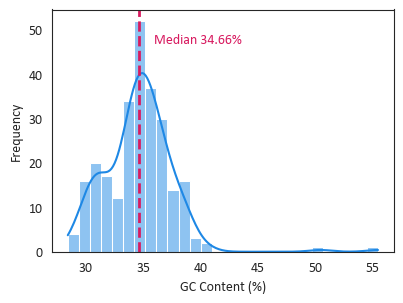

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import matplotlib as mpl
sns.set_style("white")
plt.figure(figsize=(4.135, 3.135))


# Set Calibri as the primary sans-serif font
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Calibri', 'DejaVu Sans'] # DejaVu Sans serves as a safe fallback
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
sns.histplot(gc_counts, kde=True, color="#1E88E5")
#plt.xticks(range(min(gc_counts), max(gc_counts)+1, 1))
plt.axvline(x=np.median(gc_counts), color="#D81B60", linestyle="--", linewidth=2)
plt.text(x=36, y=47, s=f"Median {round(np.median(gc_counts), 2)}%", color="#D81B60")
plt.ylabel("Frequency")
plt.xlabel("GC Content (%)")
plt.tight_layout()
plt.savefig("gc_histogram.pdf", bbox_inches='tight', format="pdf")
plt.show()

In [9]:
import re
from Bio import SeqIO
from Bio.SeqUtils import gc_fraction
import pandas as pd

KEYWORDS = {
    "glycosyltransferase": [
        r"glycosyltransfer", r"GT\d+",
        r"(rhamnosyl|fucosyl|galactosyl|glucosyl|mannosyl)transfer",
    ],
    "sugar_biosynthesis": [
        r"NDP-sugar", r"nucleotide.?sugar",
        r"sugar\s+(synthase|epimerase|mutase|dehydratase|reductase|isomerase|aminotransferase)",
        r"(dTDP|UDP|GDP|CDP)-\w+\s+(biosynthesis|synthesis|formation)",
        r"rml[ABCD]", r"wba", r"rfb",
        r"(deoxysugar|deoxy.?hexose)",
    ],
    "wzx": [
        r"wzx", r"O-antigen flippase", r"flippase",
    ],
    "wzy": [
        r"wzy", r"O-antigen polymerase",
    ],
    "wzm": [
        r"wzm", r"O-antigen ABC transporter permease",
    ],
    "wzt": [
        r"wzt", r"O-antigen ABC transporter ATP[- ]binding",
    ],
}

combined = "|".join(
    f"(?P<{group}_{i}>{pat})"
    for group, patterns in KEYWORDS.items()
    for i, pat in enumerate(patterns)
)
PATTERN = re.compile(combined, re.IGNORECASE)

QUALIFIERS_TO_CHECK = ["product", "gene", "note", "function"]

rows = []

with open("EC_Oag.gbk") as fh:
    for record in SeqIO.parse(fh, "genbank"):
        for feature in record.features:
            if feature.type != "CDS":
                continue

            text = " | ".join(
                " ".join(feature.qualifiers.get(q, []))
                for q in QUALIFIERS_TO_CHECK
            )

            m = PATTERN.search(text)
            if not m:
                continue

            enzyme_class = next(
                k for k, v in m.groupdict().items() if v is not None
            ).rsplit("_", 1)[0]

            cds_seq = feature.extract(record.seq)
            gc = round(gc_fraction(cds_seq) * 100, 2)

            rows.append({
                "record":        record.id,
                "locus_tag":     feature.qualifiers.get("locus_tag", ["?"])[0],
                "gene":          feature.qualifiers.get("gene", ["?"])[0],
                "product":       feature.qualifiers.get("product", ["?"])[0],
                "enzyme_class":  enzyme_class,
                "start":         int(feature.location.start),
                "end":           int(feature.location.end),
                "strand":        feature.location.strand,
                "cds_length_bp": len(cds_seq),
                "gc_content":    gc,
            })

df = pd.DataFrame(rows)

# Summary stats per enzyme class
summary = (
    df.groupby("enzyme_class")["gc_content"]
    .agg(count="count", mean_gc="mean", median_gc="median", std_gc="std", min_gc="min", max_gc="max")
    .round(2)
    .reset_index()
)

print(df.to_string(index=False))
print("\n── GC content summary by enzyme class ──")
print(summary.to_string(index=False))

# Save
df.to_csv("gc_hits.tsv", sep="\t", index=False)
summary.to_csv("gc_summary.tsv", sep="\t", index=False)

                          record     locus_tag gene                                                                                  product        enzyme_class  start   end  strand  cds_length_bp  gc_content
                   NZ_CP023815.1 CAOCEE_002362 rfbB                                                             dTDP-glucose 4,6-dehydratase  sugar_biosynthesis    125  1208       1           1083       47.00
                   NZ_CP023815.1 CAOCEE_002361 rfbC                                                     dTDP-4-dehydrorhamnose 3,5-epimerase  sugar_biosynthesis   1279  1822       1            543       37.02
                   NZ_CP023815.1 CAOCEE_002358  wzx                                                S88 variant O45 family O-antigen flippase                 wzx   3692  4949       1           1257       34.29
                   NZ_CP023815.1 CAOCEE_002357    ?                                                                      Glycosyltransferase glycosyltransferase   4

In [10]:
import numpy as np
from scipy import stats
from itertools import combinations

# ── Per-locus aggregation to avoid pseudoreplication ─────────────────────────
# Genes within the same locus are not independent observations: testing all
# CDS individually inflates n. Take the median GC of each enzyme class within
# each locus, then run PAIRED tests across loci containing both classes.
locus_medians = (
    df.pivot_table(index="record", columns="enzyme_class",
                   values="gc_content", aggfunc="median")
)

CLASS_ORDER = ["glycosyltransferase", "sugar_biosynthesis", "wzx", "wzy", "wzm", "wzt"]
classes = [c for c in CLASS_ORDER if c in locus_medians.columns]

def paired_test(a, b):
    """Paired tests on per-locus medians (loci containing both classes only)."""
    pair = locus_medians[[a, b]].dropna()
    n = len(pair)
    if n < 6:
        return n, np.nan, np.nan, np.nan
    w = stats.wilcoxon(pair[a], pair[b])   # Wilcoxon signed-rank (primary test)
    t = stats.ttest_rel(pair[a], pair[b])  # paired t-test (sensitivity)
    return n, w.statistic, w.pvalue, t.pvalue

# This comparison is a single pre-specified test — no multiple-comparisons
# correction is needed (unlike the exploratory pairwise table below, which is
# BH-FDR corrected across all class pairs).

# Headline comparison: glycosyltransferases vs sugar-biosynthesis genes
pair_gs = locus_medians[["glycosyltransferase", "sugar_biosynthesis"]].dropna()
n_pairs, W, p_wilcoxon, p_ttest = paired_test("glycosyltransferase", "sugar_biosynthesis")

print(f"Paired per-locus comparison (n = {n_pairs} loci containing both classes)")
print(f"  median GT GC / locus:    {pair_gs['glycosyltransferase'].median():.2f}%")
print(f"  median sugar GC / locus: {pair_gs['sugar_biosynthesis'].median():.2f}%")
print(f"  Wilcoxon signed-rank test: W = {W:.1f}, p = {p_wilcoxon:.3e}")
print(f"  paired t-test (sensitivity): p = {p_ttest:.3e}")

# All pairwise paired tests between enzyme classes
rows = []
for a, b in combinations(classes, 2):
    n, W_, p_w, p_t = paired_test(a, b)
    rows.append({
        "class_a": a, "class_b": b, "n_loci": n,
        "median_a": round(locus_medians[a].median(), 2),
        "median_b": round(locus_medians[b].median(), 2),
        "wilcoxon_p": p_w, "paired_t_p": p_t,
    })
pairwise_tests = pd.DataFrame(rows)

# Multiple-comparisons correction (Benjamini–Hochberg FDR) across all pairwise tests.
# Only valid tests (n_loci >= 6) enter the correction family.
from statsmodels.stats.multitest import multipletests
valid = pairwise_tests["wilcoxon_p"].notna()
pairwise_tests.loc[valid, "wilcoxon_q"] = multipletests(
    pairwise_tests.loc[valid, "wilcoxon_p"], method="fdr_bh"
)[1]
pairwise_tests.loc[valid, "paired_t_q"] = multipletests(
    pairwise_tests.loc[valid, "paired_t_p"], method="fdr_bh"
)[1]

print("\n── Pairwise paired tests (per-locus medians; q = BH-FDR adjusted) ──")
print(pairwise_tests.round(4).to_string(index=False))

locus_medians.round(2).to_csv("gc_locus_medians.tsv", sep="\t")
pairwise_tests.to_csv("gc_paired_tests.tsv", sep="\t", index=False)

Paired per-locus comparison (n = 96 loci containing both classes)
  median GT GC / locus:    31.10%
  median sugar GC / locus: 43.08%
  Wilcoxon signed-rank test: W = 0.0, p = 1.781e-17
  paired t-test (sensitivity): p = 6.788e-55

── Pairwise paired tests (per-locus medians; q = BH-FDR adjusted) ──
            class_a            class_b  n_loci  median_a  median_b  wilcoxon_p  paired_t_p  wilcoxon_q  paired_t_q
glycosyltransferase sugar_biosynthesis      96     31.24     42.99      0.0000      0.0000      0.0000      0.0000
glycosyltransferase                wzx     168     31.24     30.95      0.1573      0.1887      0.1769      0.2123
glycosyltransferase                wzy     172     31.24     28.84      0.0000      0.0000      0.0000      0.0000
glycosyltransferase                wzm       9     31.24     34.38      0.0273      0.0253      0.0352      0.0326
glycosyltransferase                wzt       9     31.24     38.78      0.2500      0.3054      0.2500      0.3054
 sugar_bi

In [11]:
locus_medians_melted = locus_medians.melt()

gt = locus_medians_melted[locus_medians_melted.enzyme_class == "glycosyltransferase"]
sb = locus_medians_melted[locus_medians_melted.enzyme_class == "sugar_biosynthesis"]

wzx = locus_medians_melted[locus_medians_melted.enzyme_class == "wzx"]
wzy = locus_medians_melted[locus_medians_melted.enzyme_class == "wzy"]

wzm = locus_medians_melted[locus_medians_melted.enzyme_class == "wzm"]
wzt = locus_medians_melted[locus_medians_melted.enzyme_class == "wzt"]

print(gt.value.median())

print(sb.value.median())

print(wzx.value.median())

print(wzy.value.median())

print(wzm.value.median())

print(wzt.value.median())

31.24
42.9925
30.950000000000003
28.835
34.38
38.78


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

glycosyltransferase vs. sugar_biosynthesis: Welch's t-test independent samples with Bonferroni correction, P_val:2.907e-190 t=-3.885e+01
wzy vs. wzm: Welch's t-test independent samples with Bonferroni correction, P_val:2.957e-03 t=-4.910e+00
wzx vs. wzm: Welch's t-test independent samples with Bonferroni correction, P_val:2.256e-02 t=-3.625e+00
wzy vs. wzt: Welch's t-test independent samples with Bonferroni correction, P_val:2.772e-04 t=-6.633e+00
wzx vs. wzt: Welch's t-test independent samples with Bonferroni correction, P_val:1.302e-03 t=-5.465e+00


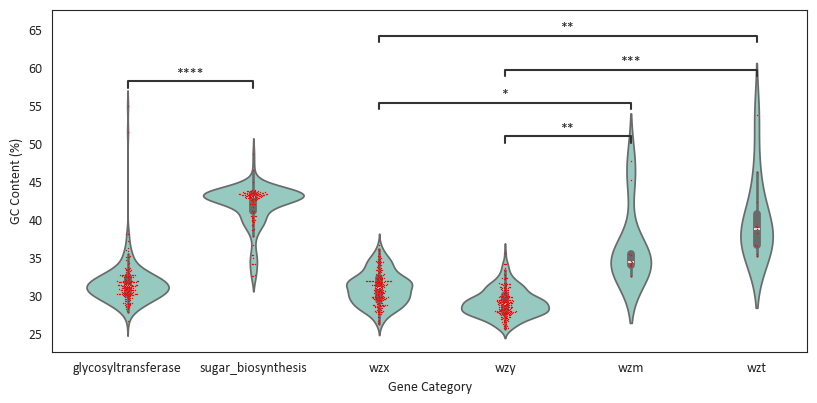

In [12]:
import seaborn as sns
from statannotations.Annotator import Annotator

plt.figure(figsize=(8.27, 4.135))
locus_medians_melted = locus_medians.melt()
sns.set_style("white")
# Set Calibri as the primary sans-serif font
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Calibri', 'DejaVu Sans'] # DejaVu Sans serves as a safe fallback
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

ax0 = sns.violinplot(locus_medians_melted, y="value", x="enzyme_class", orient="v",  order=["glycosyltransferase", "sugar_biosynthesis", "wzx", "wzy", "wzm", "wzt"])

ax = sns.swarmplot(locus_medians_melted, y="value", x="enzyme_class", orient="v",  order=["glycosyltransferase", "sugar_biosynthesis", "wzx", "wzy", "wzm", "wzt"], size=1, c="red")

# Annotate with p-values from the paired per-locus Wilcoxon tests (see cell above)
# — the old per-CDS t-test inflated n by treating genes within a locus as independent.


annotator = Annotator(ax0, [("glycosyltransferase", "sugar_biosynthesis"), ("wzx", "wzm"), ("wzx", "wzt"), ("wzy", "wzm"), ("wzy", "wzt")], data=df, y="gc_content", x="enzyme_class", order= ["glycosyltransferase", "sugar_biosynthesis", "wzx", "wzy", "wzm", "wzt"])
annotator.configure(text_format='star', loc='inside', test='t-test_welch', comparisons_correction="Bonferroni")
#annotator.set_pvalues([p_gt_bs, p_wzx_wzy])
annotator.apply_test().annotate()


#ax.set_xticks(["Glycosyltransferases", "Sugar Biosynthesis"])
plt.xlabel("Gene Category")
plt.ylabel("GC Content (%)")
plt.tight_layout()
plt.savefig("gene_compare.pdf", bbox_inches='tight', format="pdf")
plt.show()

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

glycosyltransferase vs. sugar_biosynthesis: Custom statistical test, P_val:1.781e-17
wzx vs. wzy: Custom statistical test, P_val:3.276e-24


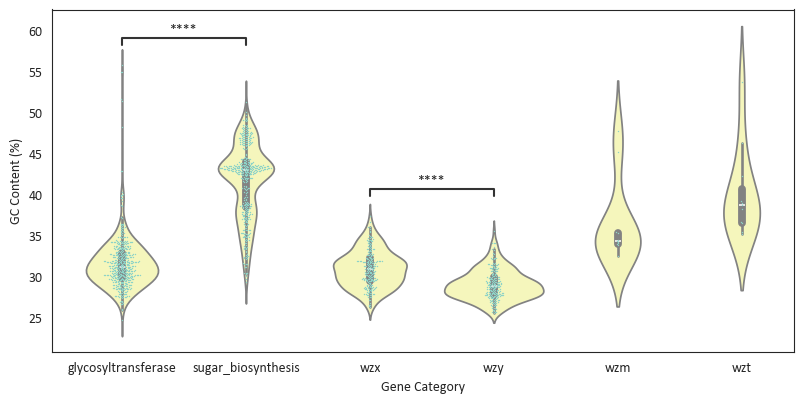

In [20]:
import seaborn as sns
from statannotations.Annotator import Annotator

plt.figure(figsize=(8.135, 4.135))

sns.set_style("white")
# Set Calibri as the primary sans-serif font
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Calibri', 'DejaVu Sans'] # DejaVu Sans serves as a safe fallback
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
ax0 = sns.swarmplot(df, y="gc_content", x="enzyme_class", size=1, order=["glycosyltransferase", "sugar_biosynthesis", "wzx", "wzy", "wzm", "wzt"])
ax = sns.violinplot(df, y="gc_content", x="enzyme_class", orient="v",  order=["glycosyltransferase", "sugar_biosynthesis", "wzx", "wzy", "wzm", "wzt"])

# Annotate with p-values from the paired per-locus Wilcoxon tests (see cell above)
# — the old per-CDS t-test inflated n by treating genes within a locus as independent.
p_gt_bs = pairwise_tests.set_index(["class_a", "class_b"]).loc[("glycosyltransferase", "sugar_biosynthesis"), "wilcoxon_p"]
p_wzx_wzy = pairwise_tests.set_index(["class_a", "class_b"]).loc[("wzx", "wzy"), "wilcoxon_p"]

annotator = Annotator(ax, [("glycosyltransferase", "sugar_biosynthesis"), ("wzx", "wzy")], data=df, y="gc_content", x="enzyme_class", order= ["glycosyltransferase", "sugar_biosynthesis", "wzx", "wzy", "wzm", "wzt"])
annotator.configure(text_format='star', loc='inside')
annotator.set_pvalues([p_gt_bs, p_wzx_wzy])
annotator.annotate()


#ax.set_xticks(["Glycosyltransferases", "Sugar Biosynthesis"])
plt.xlabel("Gene Category")
plt.ylabel("GC Content (%)")
plt.tight_layout()
plt.savefig("gene_compare.pdf", bbox_inches='tight', format="pdf")
plt.show()

In [11]:
gtf = df[df.enzyme_class == "glycosyltransferase"]

gtf.gc_content.median()

np.float64(31.0)

In [12]:
gtf = df[df.enzyme_class == "sugar_biosynthesis"]

gtf.gc_content.median()

np.float64(43.0)